# House Affordability Classification (v3 Model)
### Binary Classification with Logistic Regression & L2 Regularization (NumPy from Scratch)
---
**Key Highlights:**
- **Problem Formulation:** Median-split binary classification (Expensive: y=1 vs. Affordable: y=0, perfectly balanced 50/50)
- **Math Implementation:** Sigmoid activation, Log Loss (Binary Cross-Entropy), and numerical stability safeguards (np.clip)
- **High Accuracy:** Test Accuracy = **85.32%** (vs. 49.34% Dumb Baseline, beating Scikit-Learn 85.10%)
- **Confusion Matrix:** Balanced performance across classes (392 True Negatives, 381 True Positives)
- **L2 Regularization Experiments:** Verified weight shrinkage across lambda = 0, 1, 100 and tested small-sample overfitting behavior
---


In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

### EDA- Exploratory data analysis

In [2]:
# Loading dataset
df = pd.read_csv("training.csv")

In [3]:
df.shape

(4600, 18)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           4600 non-null   str    
 1   price          4600 non-null   float64
 2   bedrooms       4600 non-null   float64
 3   bathrooms      4600 non-null   float64
 4   sqft_living    4600 non-null   int64  
 5   sqft_lot       4600 non-null   int64  
 6   floors         4600 non-null   float64
 7   waterfront     4600 non-null   int64  
 8   view           4600 non-null   int64  
 9   condition      4600 non-null   int64  
 10  sqft_above     4600 non-null   int64  
 11  sqft_basement  4600 non-null   int64  
 12  yr_built       4600 non-null   int64  
 13  yr_renovated   4600 non-null   int64  
 14  street         4600 non-null   str    
 15  city           4600 non-null   str    
 16  statezip       4600 non-null   str    
 17  country        4600 non-null   str    
dtypes: float64(4), int6

In [5]:
print(df.duplicated().sum()) # Checking the duplicate rows

0


In [6]:
print((df.select_dtypes("number")==0).sum())

price              49
bedrooms            2
bathrooms           2
sqft_living         0
sqft_lot            0
floors              0
waterfront       4567
view             4140
condition           0
sqft_above          0
sqft_basement    2745
yr_built            0
yr_renovated     2735
dtype: int64


In [7]:
df = df.loc[(df['price']>0) & (df['bedrooms']>0) & (df['bathrooms']>0)]

In [8]:
df['price_per_sqft'] = df['price']/df['sqft_living'] # Make new column

In [9]:
# Finding the 99.5th percentile
threshold = df["price_per_sqft"].quantile(0.995)

In [10]:
df = df.loc[df['price_per_sqft'] <= threshold]

In [11]:
len(df)

4526

### Feature Engineering

In [12]:
# Feature 1: renovated
df['renovated'] = (df['yr_renovated'] > 0).astype(int) 

In [13]:
# Feature 2:
df['age'] = 2014 - df['yr_built'] 

In [14]:
df = df.drop(columns = ['date','street','statezip','country','yr_built','yr_renovated','sqft_above','price_per_sqft'])

In [15]:
# One hot-encoding of cities
df = pd.get_dummies(df, columns = ['city'])

In [16]:
df.shape

(4526, 56)

In [17]:
df

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_basement,...,city_SeaTac,city_Seattle,city_Shoreline,city_Skykomish,city_Snoqualmie,city_Snoqualmie Pass,city_Tukwila,city_Vashon,city_Woodinville,city_Yarrow Point
0,3.130000e+05,3.0,1.50,1340,7912,1.5,0,0,3,0,...,False,False,True,False,False,False,False,False,False,False
1,2.384000e+06,5.0,2.50,3650,9050,2.0,0,4,5,280,...,False,True,False,False,False,False,False,False,False,False
2,3.420000e+05,3.0,2.00,1930,11947,1.0,0,0,4,0,...,False,False,False,False,False,False,False,False,False,False
3,4.200000e+05,3.0,2.25,2000,8030,1.0,0,0,4,1000,...,False,False,False,False,False,False,False,False,False,False
4,5.500000e+05,4.0,2.50,1940,10500,1.0,0,0,4,800,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4595,3.081667e+05,3.0,1.75,1510,6360,1.0,0,0,4,0,...,False,True,False,False,False,False,False,False,False,False
4596,5.343333e+05,3.0,2.50,1460,7573,2.0,0,0,3,0,...,False,False,False,False,False,False,False,False,False,False
4597,4.169042e+05,3.0,2.50,3010,7014,2.0,0,0,3,0,...,False,False,False,False,False,False,False,False,False,False
4598,2.034000e+05,4.0,2.00,2090,6630,1.0,0,0,3,1020,...,False,True,False,False,False,False,False,False,False,False


### Y- the new target

In [18]:
median_price = df['price'].median()

In [19]:
print(f"The median price is: {median_price}$")

The median price is: 464000.0$


In [20]:
y = (df['price'] >= median_price).astype(int).to_numpy() # Making target values as binary(0s and 1s)

In [21]:
X = df.drop(columns = ['price']).astype(float).to_numpy() # astype is done because X contains mix values like bool,int,float,etc. So by default dtype will be 'O' object

In [22]:
X.dtype

dtype('float64')

In [23]:
print(np.unique(y, return_counts=True)) # Tells the count of unique values(0s and 1s here) in array

(array([0, 1]), array([2260, 2266]))


2260 and 2266. But not 2263 each because we have taken one side < and on other >=. So the houses which are = to median goes into y = 1 group.

### Feature scaling

In [24]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [25]:
print("The shape of X_train set is:", X_train.shape)
print("The shape of X_test set is:", X_test.shape)

The shape of X_train set is: (3620, 55)
The shape of X_test set is: (906, 55)


In [26]:
# Z-score Normalization
mu = np.mean(X_train, axis = 0)
sigma = np.std(X_train, axis = 0)
sigma = np.where(sigma == 0, 1, sigma) # Replaces every zero in the sigma array with the number 1. Prevents value to become inf. 

In [27]:
X_train_norm = (X_train - mu) / sigma
X_test_norm = (X_test - mu) / sigma

In [28]:
# 1. Find the majority class from training set
majority_class = 1 if np.mean(y_train == 1) >= 0.5 else 0 # This rule we have created here
print(f"Majority class from taining set is: {majority_class}")

Majority class from taining set is: 1


In [29]:
# 2. Dumb Baseline Model predicts the same for test set for every house
baseline_preds = np.full(shape=len(y_test), fill_value=majority_class)

# 3. Now let's check it's baseline(Dumb's model) accuracy on test set:
baseline_acc = np.mean(baseline_preds == y_test) # Now it takes into acc. wherever the accuracy is 1. This caan be done directly but the process must be cleared.
print(f"True Baseline Accuracy on Test Set: {baseline_acc * 100:.2f}%")

True Baseline Accuracy on Test Set: 49.34%


### Model training

In [30]:
# Function 1: sigmoid(z)
def sigmoid(z):
    g_z = 1/ (1+ np.exp(-z))

    return g_z

In [31]:
# Logistic cost fxn 
def compute_cost_logistic(X, y, w, b):
    z = np.dot(X,w) + b
    f = sigmoid(z)
    f = np.clip(f, 1e-15, 1 - 1e-15) # For numerical stability. log(0) crash na ho.

    J_wb = -np.mean(y*np.log(f) + (1-y)*np.log(1-f))

    return J_wb

In [32]:
# Gradient for logistic
def compute_gradient_logistic(X, y, w, b):
    m,n = X.shape
    f = sigmoid(np.dot(X,w) + b)
    err = f - y

    dj_db = np.mean(err)
    dj_dw = np.dot(X.T, err)/ m 

    return dj_dw, dj_db

In [33]:
# Sanity check
n = X_train_norm.shape[1]
w_init = np.zeros(n)
b_init = 0
cost_init = compute_cost_logistic(X_train_norm, y_train, w_init, b_init)
dj_dw_init, dj_db_init = compute_gradient_logistic(X_train_norm, y_train, w_init, b_init)

print(f"Initial Cost at w=0, b=0: {cost_init:.4f}")
print(f"Initial dj_db: {dj_db_init:.4f}")
print(f"dj_dw shape: {dj_dw_init.shape}")

Initial Cost at w=0, b=0: 0.6931
Initial dj_db: -0.0025
dj_dw shape: (55,)


In [34]:
# Gradient descent for logistic fxn
def gradient_descent_logistic(X, y, w, b, alpha, num_iters, compute_cost_logistic, compute_gradient_logistic):
    J_history = []

    for i in range(num_iters):
        dj_dw, dj_db = compute_gradient_logistic(X, y, w, b)

        w = w - alpha * dj_dw
        b = b - alpha * dj_db

        # Save the cost
        if i < 100000:
            J_history.append(compute_cost_logistic(X,y,w,b))

            if i % (num_iters // 10) == 0:
                print((f"Iteration {i:4d}: Cost {J_history[-1]:.4f}"))
    return w,b,J_history

In [35]:
alpha = 0.1 
num_iters = 2000
w_init = np.zeros(n)
b_init = 0.0
w_final, b_final, J_history = gradient_descent_logistic(X_train_norm, y_train, w_init, b_init, alpha, num_iters, compute_cost_logistic, compute_gradient_logistic)

Iteration    0: Cost 0.6684
Iteration  200: Cost 0.3509
Iteration  400: Cost 0.3365
Iteration  600: Cost 0.3309
Iteration  800: Cost 0.3281
Iteration 1000: Cost 0.3264
Iteration 1200: Cost 0.3254
Iteration 1400: Cost 0.3248
Iteration 1600: Cost 0.3244
Iteration 1800: Cost 0.3241


In [36]:
print(w_final)

[-2.19116436e-01  4.84028576e-01  2.43859581e+00  2.90786681e-01
  3.56028068e-01  2.60747273e-01  3.84929331e-01  2.08639973e-01
 -4.31018389e-01 -2.44694353e-03  5.40985837e-01 -1.44997226e-01
 -7.09551607e-01  1.11556508e-01  5.41847526e-01  2.65648951e-02
 -1.73725872e-02 -1.61497062e-01 -1.07107509e-01  1.91321009e-01
 -3.65606473e-01 -3.62196222e-01 -1.26918529e-01 -2.64583269e-01
  2.36693789e-02 -5.98520083e-01 -6.91819473e-02  2.80124651e-01
 -3.05429676e-02 -8.03470336e-01  2.80310331e-01  6.18349167e-04
 -3.68311837e-01 -7.79027745e-02  4.15805186e-01 -7.48302646e-02
  1.08987794e-01 -4.37406831e-02 -1.78342792e-01 -1.73455351e-01
  3.20235046e-02  3.01856595e-02  5.30435800e-01 -3.86013192e-01
  3.95123998e-01 -4.00730214e-01  5.95336804e-01 -9.94098870e-02
 -1.53872168e-01  1.78660498e-02  8.89667799e-02 -3.56057999e-01
 -1.29993308e-01  1.60858998e-01  4.88882958e-02]


### Predictions & Evaluation

In [37]:
# Prediction Function
z = np.dot(X_test_norm, w_final) + b_final
p = sigmoid(z) # Predicted probabilites on testing set
preds = (p >= 0.5).astype(int)

In [38]:
# Test Accuracy
acc = np.mean(preds == y_test)
print(f"Accuracy of our model is: {acc*100:.2f}%")

Accuracy of our model is: 85.32%


##### Confusion Matrix

In [39]:
cm = confusion_matrix(y_test, preds)
print("Confusion Matrix:\n", cm)

Confusion Matrix:
 [[392  67]
 [ 66 381]]


In [40]:
tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()

print(f"True Negatives  (True Affordable): {tn} houses")
print(f"False Positives (Mistakenly Expensive): {fp} houses")
print(f"False Negatives (Mistakenly Affordable): {fn} houses")
print(f"True Positives  (True Expensive): {tp} houses")

True Negatives  (True Affordable): 392 houses
False Positives (Mistakenly Expensive): 67 houses
False Negatives (Mistakenly Affordable): 66 houses
True Positives  (True Expensive): 381 houses


In [41]:
# Matching with Scikit-learn
model = LogisticRegression(max_iter=1000)
model.fit(X_train_norm, y_train)
sklearn_acc = model.score(X_test_norm, y_test)
print(f"Sklearn Test Accuracy: {sklearn_acc * 100:.2f}%")

Sklearn Test Accuracy: 85.10%


### Logistic Regression with Regularization(λ)

Why do we need this?
In our model 55 features are there(in which 44 are of cities). If any city in which in training data contains only 1 or 2 house, then model may increase the weight(overfit) of that specific city.

Regularization controls the weight.

In [42]:
def regularized_cost(X,y,w,b,lambdaa):
    m = X.shape[0]
    z = np.dot(X,w) + b
    f = sigmoid(z)
    f = np.clip(f, 1e-15, 1 - 1e-15) # For numerical stability. log(0) crash na ho.

    J_wb = -np.mean(y*np.log(f) + (1-y)*np.log(1-f))
    R_J_wb = J_wb + (lambdaa/(2*m)) * np.sum(w**2)
    return R_J_wb

In [43]:
def regularized_gradient(X,y,w,b,lambdaa):
    m,n = X.shape
    f = sigmoid(np.dot(X,w) + b)
    err = f - y

    dj_db = np.mean(err)
    R_dj_dw = np.dot(X.T, err)/ m + (lambdaa/m) * w 

    return R_dj_dw, dj_db

In [44]:
# Gradient descent for regularized logistic fxn
def gradient_descent_logistic(X, y, w, b, alpha, num_iters, lambdaa, regularized_cost, regularized_gradient):
    J_history = []

    for i in range(num_iters):
        dj_dw, dj_db = regularized_gradient(X, y, w, b, lambdaa)

        w = w - alpha * dj_dw
        b = b - alpha * dj_db

        # Save the cost
        if i < 100000:
            J_history.append(regularized_cost(X,y,w,b,lambdaa))

            if i % (num_iters // 10) == 0:
                print((f"Iteration {i:4d}: Cost {J_history[-1]:.4f}"))
                
    return w,b,J_history

In [45]:
alpha = 0.1 
num_iters = 2000
w_init = np.zeros(n)
b_init = 0.0
lambdaa = 0 # No regularization our current model
w_final1, b_final1, J_history1 = gradient_descent_logistic(X_train_norm, y_train, w_init, b_init, alpha, num_iters, lambdaa, regularized_cost, regularized_gradient)
print(w_final1)

Iteration    0: Cost 0.6684
Iteration  200: Cost 0.3509
Iteration  400: Cost 0.3365
Iteration  600: Cost 0.3309
Iteration  800: Cost 0.3281
Iteration 1000: Cost 0.3264
Iteration 1200: Cost 0.3254
Iteration 1400: Cost 0.3248
Iteration 1600: Cost 0.3244
Iteration 1800: Cost 0.3241
[-2.19116436e-01  4.84028576e-01  2.43859581e+00  2.90786681e-01
  3.56028068e-01  2.60747273e-01  3.84929331e-01  2.08639973e-01
 -4.31018389e-01 -2.44694353e-03  5.40985837e-01 -1.44997226e-01
 -7.09551607e-01  1.11556508e-01  5.41847526e-01  2.65648951e-02
 -1.73725872e-02 -1.61497062e-01 -1.07107509e-01  1.91321009e-01
 -3.65606473e-01 -3.62196222e-01 -1.26918529e-01 -2.64583269e-01
  2.36693789e-02 -5.98520083e-01 -6.91819473e-02  2.80124651e-01
 -3.05429676e-02 -8.03470336e-01  2.80310331e-01  6.18349167e-04
 -3.68311837e-01 -7.79027745e-02  4.15805186e-01 -7.48302646e-02
  1.08987794e-01 -4.37406831e-02 -1.78342792e-01 -1.73455351e-01
  3.20235046e-02  3.01856595e-02  5.30435800e-01 -3.86013192e-01
  3.9

In [46]:
lambdaa = 1.0 # Balanced regularization
w_final2, b_final2, J_history2 = gradient_descent_logistic(X_train_norm, y_train, w_init, b_init, alpha, num_iters, lambdaa, regularized_cost, regularized_gradient)
print(w_final2)

Iteration    0: Cost 0.6684
Iteration  200: Cost 0.3515
Iteration  400: Cost 0.3374
Iteration  600: Cost 0.3321
Iteration  800: Cost 0.3294
Iteration 1000: Cost 0.3279
Iteration 1200: Cost 0.3269
Iteration 1400: Cost 0.3264
Iteration 1600: Cost 0.3260
Iteration 1800: Cost 0.3258
[-2.10930651e-01  4.83748561e-01  2.39555721e+00  2.86566447e-01
  3.56618520e-01  2.56380434e-01  3.82234877e-01  2.07206257e-01
 -4.17156545e-01 -2.39954483e-03  5.36214285e-01 -1.41375995e-01
 -6.99554574e-01  1.09001845e-01  5.36199303e-01  2.57629483e-02
 -1.76010858e-02 -1.60958168e-01 -1.05117359e-01  1.86726008e-01
 -3.59859097e-01 -3.57927968e-01 -1.25511405e-01 -2.61127443e-01
  2.30320027e-02 -5.90093309e-01 -6.73869067e-02  2.77360440e-01
 -3.11076773e-02 -7.92031589e-01  2.76493031e-01 -9.07630782e-05
 -3.64565559e-01 -7.60413320e-02  4.09237412e-01 -7.28367967e-02
  1.08224432e-01 -4.31935458e-02 -1.76779392e-01 -1.69021589e-01
  3.09887672e-02  2.99571511e-02  5.25708677e-01 -3.82592197e-01
  3.9

In [47]:
lambdaa = 100.0 # Over-regularization / Underfitting — weights shrink very much
w_final3, b_final3, J_history3 = gradient_descent_logistic(X_train_norm, y_train, w_init, b_init, alpha, num_iters, lambdaa, regularized_cost, regularized_gradient)
print(w_final3)

Iteration    0: Cost 0.6684
Iteration  200: Cost 0.4004
Iteration  400: Cost 0.3984
Iteration  600: Cost 0.3982
Iteration  800: Cost 0.3982
Iteration 1000: Cost 0.3982
Iteration 1200: Cost 0.3982
Iteration 1400: Cost 0.3982
Iteration 1600: Cost 0.3982
Iteration 1800: Cost 0.3982
[ 0.04775985  0.43256096  1.06401322  0.16138131  0.3340391   0.12305349
  0.27595561  0.15166167 -0.00807821 -0.00317843  0.31573836 -0.06657127
 -0.39321991  0.05462148  0.34956319  0.00404628 -0.01951896 -0.12716382
 -0.04466094  0.08773404 -0.19366549 -0.20934835 -0.08078896 -0.14896586
  0.0082572  -0.33780663 -0.03431951  0.18857267 -0.04313681 -0.4552813
  0.16143013 -0.01798239 -0.24247283 -0.01122103  0.22364165 -0.03572062
  0.08319936 -0.02132367 -0.11934795 -0.08121625  0.0170927   0.02260619
  0.36199686 -0.26727788  0.27836414 -0.17038678  0.28387092 -0.12123314
 -0.06530541  0.04074935  0.04141896 -0.16311547 -0.05676999  0.12785203
  0.02470798]


In [48]:
print("Above cost is big as compare to pre. because model underfits here as much penalty is added as lambda is high")

Above cost is big as compare to pre. because model underfits here as much penalty is added as lambda is high


In [49]:
# ALl three models prediction on train set:
preds_0 = (sigmoid(np.dot(X_train_norm, w_final1) + b_final1) >= 0.5).astype(int)
preds_1 = (sigmoid(np.dot(X_train_norm, w_final2) + b_final2) >= 0.5).astype(int)
preds_100 = (sigmoid(np.dot(X_train_norm, w_final3) + b_final3) >= 0.5).astype(int)

# Weights overall size (L2 Norm / Magnitude)
norm_0 = np.linalg.norm(w_final1) # Tells how much overall weight is effected(Vectors Total Length / Magnitude).
norm_1 = np.linalg.norm(w_final2)
norm_100 = np.linalg.norm(w_final3) # Underfits because we have plenty of eg.s as comp. to features so we don't need to regularize that much

print(f"Lambda = 0   -> Train Acc: {np.mean(preds_0 == y_train)*100:.2f}% | ||w||: {norm_0:.2f}")
print(f"Lambda = 1   -> Train Acc: {np.mean(preds_1 == y_train)*100:.2f}% | ||w||: {norm_1:.2f}")
print(f"Lambda = 100 -> Train Acc: {np.mean(preds_100 == y_train)*100:.2f}% | ||w||: {norm_100:.2f}")

Lambda = 0   -> Train Acc: 85.61% | ||w||: 3.36
Lambda = 1   -> Train Acc: 85.58% | ||w||: 3.31
Lambda = 100 -> Train Acc: 84.64% | ||w||: 1.75


In [50]:
# ALl three models prediction on test set:
preds_0 = (sigmoid(np.dot(X_test_norm, w_final1) + b_final1) >= 0.5).astype(int)
preds_1 = (sigmoid(np.dot(X_test_norm, w_final2) + b_final2) >= 0.5).astype(int)
preds_100 = (sigmoid(np.dot(X_test_norm, w_final3) + b_final3) >= 0.5).astype(int)

# Weights overall size (L2 Norm / Magnitude)
norm_0 = np.linalg.norm(w_final1) # Tells how much overall weight is effected(Vectors Total Length / Magnitude).
norm_1 = np.linalg.norm(w_final2)
norm_100 = np.linalg.norm(w_final3) # Underfits because we have plenty of eg.s as comp. to features so we don't need to regularize that much

print(f"Lambda = 0   -> Test Acc: {np.mean(preds_0 == y_test)*100:.2f}% | ||w||: {norm_0:.2f}")
print(f"Lambda = 1   -> Test Acc: {np.mean(preds_1 == y_test)*100:.2f}% | ||w||: {norm_1:.2f}")
print(f"Lambda = 100 -> Test Acc: {np.mean(preds_100 == y_test)*100:.2f}% | ||w||: {norm_100:.2f}")

Lambda = 0   -> Test Acc: 85.32% | ||w||: 3.36
Lambda = 1   -> Test Acc: 85.32% | ||w||: 3.31
Lambda = 100 -> Test Acc: 83.77% | ||w||: 1.75


### Overfitting case handling with regularization
If we take 50 egs.(m<n) then model overfits see

In [51]:
# 1. Only 50 training examples
X_small = X_train_norm[:50]
y_small = y_train[:50]

print(f"Small Training Set Shape: {X_small.shape} (50 houses, 55 features!)")

Small Training Set Shape: (50, 55) (50 houses, 55 features!)


In [52]:
# 2. Case A: Without Regularization (lambda = 0)
w_init = np.zeros(X_small.shape[1])
b_init = 0.0

w_no_reg, b_no_reg, _ = gradient_descent_logistic(
    X_small, y_small, w_init, b_init, 
    alpha=0.1, num_iters=3000, lambdaa=0.0,
    regularized_cost=regularized_cost, 
    regularized_gradient=regularized_gradient
)

Iteration    0: Cost 0.6566
Iteration  300: Cost 0.2290
Iteration  600: Cost 0.1999
Iteration  900: Cost 0.1863
Iteration 1200: Cost 0.1779
Iteration 1500: Cost 0.1721
Iteration 1800: Cost 0.1677
Iteration 2100: Cost 0.1642
Iteration 2400: Cost 0.1613
Iteration 2700: Cost 0.1589


In [53]:
# 3. Case B: With Regularization (lambda = 2.0)
w_reg, b_reg, _ = gradient_descent_logistic(
    X_small, y_small, w_init, b_init, 
    alpha=0.1, num_iters=3000, lambdaa=2,
    regularized_cost=regularized_cost, 
    regularized_gradient=regularized_gradient
)

Iteration    0: Cost 0.6566
Iteration  300: Cost 0.3464
Iteration  600: Cost 0.3461
Iteration  900: Cost 0.3461
Iteration 1200: Cost 0.3461
Iteration 1500: Cost 0.3461
Iteration 1800: Cost 0.3461
Iteration 2100: Cost 0.3461
Iteration 2400: Cost 0.3461
Iteration 2700: Cost 0.3461


In [54]:
# 4. Accuracy Check: Train vs Test on both models
# Predictions on small train set
p_train_no_reg = (sigmoid(np.dot(X_small, w_no_reg) + b_no_reg) >= 0.5).astype(int)
p_train_reg    = (sigmoid(np.dot(X_small, w_reg) + b_reg) >= 0.5).astype(int)

# Predictions on full unseen test set (906 houses)
p_test_no_reg  = (sigmoid(np.dot(X_test_norm, w_no_reg) + b_no_reg) >= 0.5).astype(int)
p_test_reg     = (sigmoid(np.dot(X_test_norm, w_reg) + b_reg) >= 0.5).astype(int)

print("\n--- RESULTS ON SMALL DATA (50 examples) ---")
print(f"No Reg (lambda=0):   Train Acc = {np.mean(p_train_no_reg == y_small)*100:.2f}% | Test Acc = {np.mean(p_test_no_reg == y_test)*100:.2f}% | ||w|| = {np.linalg.norm(w_no_reg):.2f}")
print(f"With Reg (lambda=2): Train Acc = {np.mean(p_train_reg == y_small)*100:.2f}% | Test Acc = {np.mean(p_test_reg == y_test)*100:.2f}% | ||w|| = {np.linalg.norm(w_reg):.2f}")


--- RESULTS ON SMALL DATA (50 examples) ---
No Reg (lambda=0):   Train Acc = 94.00% | Test Acc = 72.52% | ||w|| = 6.45
With Reg (lambda=2): Train Acc = 94.00% | Test Acc = 72.19% | ||w|| = 1.87


Above we can see that the massive reductions in weights. That's all regularization is! It prevents weights from exploding.

### Visualizations

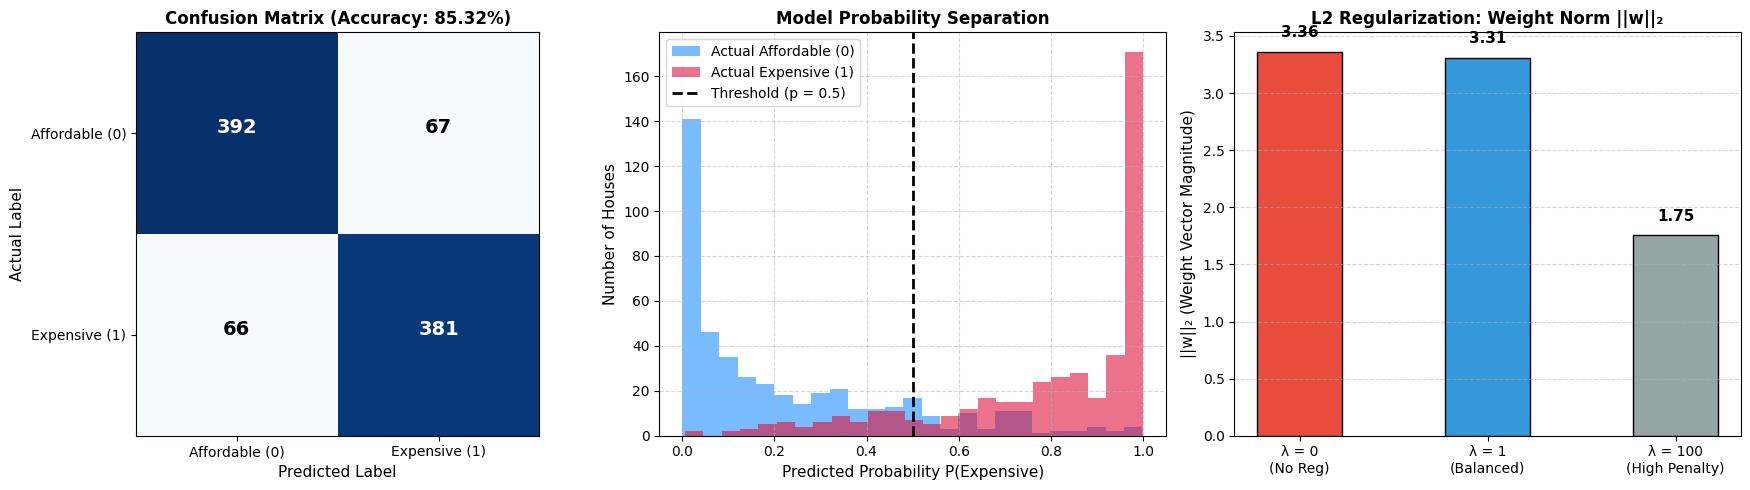

In [58]:
# v3 VISUAL DASHBOARD: Confusion Matrix, Probabilities & Regularization

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# 1. Confusion Matrix Heatmap
im = ax[0].imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
ax[0].set_title(f"Confusion Matrix (Accuracy: {acc*100:.2f}%)", fontsize=12, fontweight='bold')
classes = ['Affordable (0)', 'Expensive (1)']
tick_marks = np.arange(len(classes))
ax[0].set_xticks(tick_marks)
ax[0].set_xticklabels(classes, fontsize=10)
ax[0].set_yticks(tick_marks)
ax[0].set_yticklabels(classes, fontsize=10)

thresh = cm.max() / 2.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax[0].text(j, i, f"{cm[i, j]}",
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black",
                 fontsize=14, fontweight='bold')
ax[0].set_ylabel('Actual Label', fontsize=11)
ax[0].set_xlabel('Predicted Label', fontsize=11)

# 2. Predicted Probabilities Distribution (Confidence)
p_test = sigmoid(np.dot(X_test_norm, w_final) + b_final)
ax[1].hist(p_test[y_test == 0], bins=25, alpha=0.6, color='dodgerblue', label='Actual Affordable (0)')
ax[1].hist(p_test[y_test == 1], bins=25, alpha=0.6, color='crimson', label='Actual Expensive (1)')
ax[1].axvline(0.5, color='black', linestyle='--', lw=2, label='Threshold (p = 0.5)')
ax[1].set_title("Model Probability Separation", fontsize=12, fontweight='bold')
ax[1].set_xlabel("Predicted Probability P(Expensive)", fontsize=11)
ax[1].set_ylabel("Number of Houses", fontsize=11)
ax[1].legend()
ax[1].grid(True, linestyle='--', alpha=0.5)

# 3. Regularization Shrink Effect (||w|| vs Lambda)
lambdas_str = ['λ = 0\n(No Reg)', 'λ = 1\n(Balanced)', 'λ = 100\n(High Penalty)']
norms = [np.linalg.norm(w_final1), np.linalg.norm(w_final2), np.linalg.norm(w_final3)]

bars = ax[2].bar(lambdas_str, norms, color=['#e74c3c', '#3498db', '#95a5a6'], width=0.45, edgecolor='black')
ax[2].set_title("L2 Regularization: Weight Norm ||w||₂", fontsize=12, fontweight='bold')
ax[2].set_ylabel("||w||₂ (Weight Vector Magnitude)", fontsize=11)
for bar in bars:
    yval = bar.get_height()
    ax[2].text(bar.get_x() + bar.get_width()/2.0, yval + 0.1, f"{yval:.2f}", 
               ha='center', va='bottom', fontsize=11, fontweight='bold')
ax[2].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()